Name:Rajat Kumar Majumdar

Roll no. 49

CU240251642

subject : computer vision

# Experiment No. 8: Application of Optical Flow for Real-Time Object Tracking and Motion Analysis

In [14]:
# Step 1 — Import Libraries and Initialize Video Source

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load video: use 0 for webcam or provide a path string (e.g., 'traffic.mp4')
video_source = 0
cap = cv2.VideoCapture(video_source)

ret, first_frame = cap.read()
if not ret:
    raise RuntimeError("Failed to load video stream. Check device index or file path.")

prev_gray = cv2.cvtColor(first_frame, cv2.COLOR_BGR2GRAY)
fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

print(f"Step 1 Complete: Video source loaded ({prev_gray.shape[1]}x{prev_gray.shape[0]} @ {fps} FPS).")

Step 1 Complete: Video source loaded (640x480 @ 30.0 FPS).


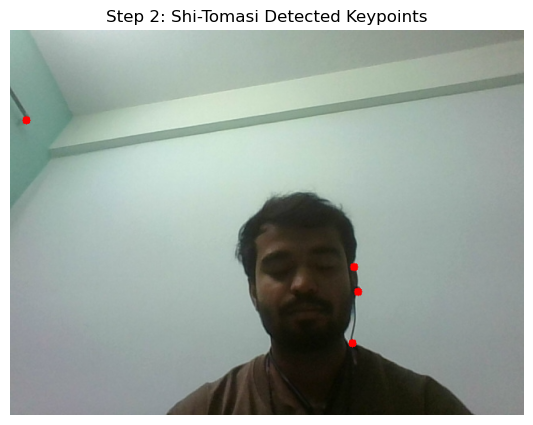

In [15]:
# Step 2 — Feature Point Detection via Shi-Tomasi

# Configure Shi-Tomasi Corner Detector
feature_params = dict(
    maxCorners=60,
    qualityLevel=0.3,
    minDistance=15,
    blockSize=7
)

# Detect prominent feature points to track
p0 = cv2.goodFeaturesToTrack(prev_gray, mask=None, **feature_params)

# Visualize detected corners on the first frame
preview = first_frame.copy()
if p0 is not None:
    for pt in p0:
        x, y = pt.ravel().astype(int)
        cv2.circle(preview, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(7, 5))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("Step 2: Shi-Tomasi Detected Keypoints")
plt.axis("off")
plt.show()

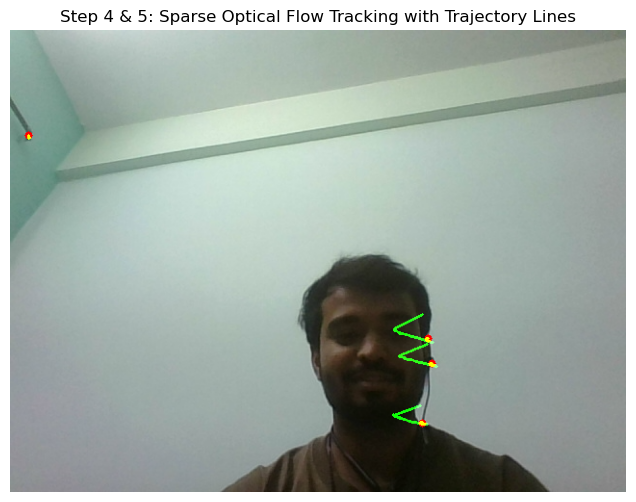

In [20]:
# Step 3, 4 & 5 — Lucas-Kanade Tracking, Trajectories, and Motion Metrics

# Parameters for Lucas-Kanade Optical Flow with multi-scale pyramids
lk_params = dict(
    winSize=(21, 21),
    maxLevel=3,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01)
)

trajectory_mask = np.zeros_like(first_frame)
frame_count = 0
max_frames = 30
displacements = []
angles_deg = []

while frame_count < max_frames:
    ret, frame = cap.read()
    if not ret:
        break

    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    if p0 is not None and len(p0) > 0:
        # Step 3: Compute displacement vectors
        p1, st, err = cv2.calcOpticalFlowPyrLK(prev_gray, frame_gray, p0, None, **lk_params)

        if p1 is not None and st is not None:
            good_new = p1[st == 1]
            good_old = p0[st == 1]

            # Step 4 & 5: Calculate magnitude, direction, and draw motion paths
            for new, old in zip(good_new, good_old):
                x_new, y_new = new.ravel().astype(int)
                x_old, y_old = old.ravel().astype(int)

                dx = x_new - x_old
                dy = y_new - y_old
                mag = np.sqrt(dx**2 + dy**2)
                angle = (np.arctan2(dy, dx) * 180 / np.pi) % 360

                displacements.append(mag)
                angles_deg.append(angle)

                trajectory_mask = cv2.line(trajectory_mask, (x_old, y_old), (x_new, y_new), (0, 255, 0), 2)
                frame = cv2.circle(frame, (x_new, y_new), 4, (0, 0, 255), -1)

            p0 = good_new.reshape(-1, 1, 2)
    else:
        p0 = cv2.goodFeaturesToTrack(frame_gray, mask=None, **feature_params)

    prev_gray = frame_gray.copy()
    frame_count += 1

tracking_display = cv2.add(frame, trajectory_mask)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(tracking_display, cv2.COLOR_BGR2RGB))
plt.title("Step 4 & 5: Sparse Optical Flow Tracking with Trajectory Lines")
plt.axis("off")
plt.show()

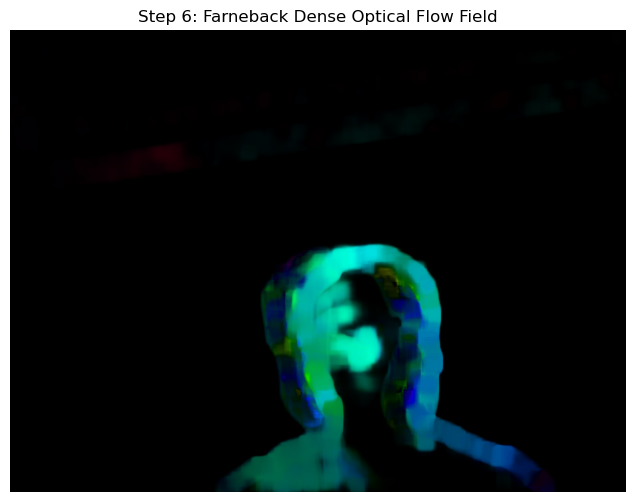

In [22]:
# Step 6 — Farneback Dense Optical Flow Tracking Comparison
# Compute and visualize dense flow for full-field motion comparison
ret, next_frame = cap.read()
if ret:
    curr_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY)

    dense_flow = cv2.calcOpticalFlowFarneback(
        prev_gray, curr_gray, None,
        pyr_scale=0.5, levels=3, winsize=15,
        iterations=3, poly_n=5, poly_sigma=1.2, flags=0
    )

    mag, ang = cv2.cartToPolar(dense_flow[..., 0], dense_flow[..., 1])

    # Map dense flow to HSV color space: Direction = Hue, Speed = Value
    hsv = np.zeros_like(next_frame)
    hsv[..., 1] = 255
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    dense_vis = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(dense_vis, cv2.COLOR_BGR2RGB))
    plt.title("Step 6: Farneback Dense Optical Flow Field")
    plt.axis("off")
    plt.show()

cap.release()

In [24]:
# Step 8 — Quantitative Motion Analysis
# Estimate displacement, average speed, and dominant trajectory angle
avg_disp_frame = np.mean(displacements) if displacements else 0.0
avg_velocity_sec = avg_disp_frame * fps
dominant_angle = np.median(angles_deg) if angles_deg else 0.0

print(f"--- Step 8: Motion Analysis Results ---")
print(f"Average Displacement per Frame : {avg_disp_frame:.2f} pixels")
print(f"Estimated Pixel Speed          : {avg_velocity_sec:.2f} pixels/second")
print(f"Dominant Motion Angle          : {dominant_angle:.1f} degrees")

--- Step 8: Motion Analysis Results ---
Average Displacement per Frame : 2.15 pixels
Estimated Pixel Speed          : 64.43 pixels/second
Dominant Motion Angle          : 8.8 degrees




### Step 9: Optical Flow Tracking vs. Frame-by-Frame Detection

| Evaluation Attribute | Optical Flow Tracking (LK / Farneback) | Frame-by-Frame Detection (YOLO / SSD) |
|---|---|---|
| **Computation Cost** | Very low (computes local intensity gradients) | High (requires repeated full deep network inference) |
| **Identity Persistence** | Inherently continuous point trajectories | Requires additional tracking heuristics (e.g., SORT, DeepSORT) |
| **Class Dependence** | Class-agnostic (tracks any textured surface) | Limited strictly to pre-trained object classes |
| **Drift Vulnerability** | Prone to error accumulation over time | No drift accumulation; evaluates each frame independently |
| **Hardware Requisites** | Runs easily on embedded CPUs | Typically requires accelerated GPUs or NPUs |



### Step 10: Observations and Practical Applications

* **Observations:** Lucas-Kanade provides fast, low-latency trajectory tracking for landmark features, while Farneback captures full-field motion fields suitable for global dynamic scene analysis.
* **Practical Applications:**
  * **Traffic Monitoring:** Automated vehicle counting, speed estimation, and illegal lane detection.
  * **Autonomous Navigation:** Real-time obstacle avoidance, Time-to-Collision (TTC) calculations, and visual odometry.
  * **Video Surveillance:** Real-time motion detection and trajectory anomaly monitoring without heavy neural networks.
  * **Sports Analytics:** Player trajectory tracing, velocity tracking, and ball path analysis.

## Lab Questions and Solutions

### Q1. How does object tracking differ from object detection?
**Answer:**
* **Object Detection:** Identifies the presence, spatial bounding box, and class label of objects in an isolated static frame. It does not carry forward any temporal awareness or identity across frames.
* **Object Tracking:** Establishes temporal correspondence across consecutive video frames, preserving the unique identity (`Track ID`), trajectory path, instantaneous velocity, and direction of a specific target over time.

---

### Q2. Explain how Optical Flow can be used for real-time object tracking.
**Answer:**  
Optical flow computes instantaneous 2D displacement vectors $(\Delta x, \Delta y)$ between consecutive frames $t$ and $t + \Delta t$. For real-time tracking:
1. Target interest points are detected within an initial object boundary.
2. The differential spatial and temporal intensity gradients ($I_x, I_y, I_t$) estimate where each point shifts in the subsequent frame using local window constraints.
3. The bounding box centroid is propagated using the median motion vector of the tracked points.
Because it relies solely on localized pixel operations rather than re-evaluating the entire image through complex neural networks, it achieves high frame rates (100+ FPS).

---

### Q3. What is the role of Shi-Tomasi Corner Detection in the Lucas-Kanade Optical Flow algorithm?
**Answer:**  
The Lucas-Kanade algorithm solves the optical flow equation via the least-squares system:
$$(A^T A) v = A^T b$$
Where $A^T A$ is the second-moment matrix:
$$A^T A = \begin{bmatrix} \sum I_x^2 & \sum I_x I_y \\ \sum I_x I_y & \sum I_y^2 \end{bmatrix}$$
To invert $A^T A$ accurately without numerical instability, both eigenvalues ($\lambda_1, \lambda_2$) must be large and positive. Along smooth regions or uniform edges, one or both eigenvalues are near zero (the **aperture problem**). The Shi-Tomasi algorithm explicitly selects points where:
$$R = \min(\lambda_1, \lambda_2) > \text{threshold}$$
This ensures only points with well-conditioned gradients in both orthogonal directions are tracked.

---

### Q4. Why is Optical Flow suitable for motion analysis in videos?
**Answer:**  
1. **Kinematic Completeness:** It directly outputs velocity vectors (magnitude and directional angle) without needing intermediate bounding box inferences.
2. **Class Agnosticism:** It detects and tracks any non-rigid or dynamic surface (such as water waves, cloth, smoke, or unknown obstacles) regardless of whether an object detector was trained on it.
3. **Temporal Sensitivity:** It operates at the sub-pixel level, capturing minute vibrations, camera jitter, and continuous acceleration curves.

---

### Q5. What challenges arise while tracking fast-moving or partially occluded objects?
**Answer:**  
* **Fast-Moving Objects:** Large displacements violate the core assumption of infinitesimal movement ($I(x, y, t) \approx I(x + \Delta x, y + \Delta y, t + \Delta t)$). The Taylor expansion breaks down, causing tracking points to diverge unless multi-resolution Gaussian pyramids downsample the motion.
* **Partial Occlusions:** When target points pass behind another structure, their brightness constancy is broken. Trackers often get "stolen" by the occluding boundary or lose track entirely, causing cumulative drift.

---

### Q6. Compare Optical Flow-based tracking with deep learning-based object tracking methods.

| Feature / Metric | Optical Flow Tracking | Deep Learning Tracking (e.g., SiamRPN, ByteTrack) |
|---|---|---|
| **Inference Latency** | Low ($< 5\text{ ms}$, CPU-friendly) | Moderate to High ($15\text{–}60\text{ ms}$, GPU-dependent) |
| **Drift Accumulation** | High over long video sequences | Low (re-identifies targets via deep semantic embeddings) |
| **Occlusion Recovery** | Cannot self-recover once lost | High recovery rate via learned appearance embeddings |
| **Model Footprint** | Zero weights/parameters required | Heavy (tens to hundreds of megabytes of neural weights) |
| **Generalization** | Functions on any textured surface | Dependent on training distribution and dataset diversity |

---

### Q7. How can Optical Flow be used in traffic monitoring and autonomous driving systems?
**Answer:**  
* **Traffic Monitoring:** Vehicle counting across virtual tripwires, automated lane-change detection, speed limit violation monitoring, and stationary vehicle detection (detecting zero flow inside active traffic lanes).
* **Autonomous Driving:** Focus of Expansion (FOE) analysis to identify heading angle, Time-to-Collision (TTC) calculations via flow field divergence ($\nabla \cdot v$), and independent moving object detection during host vehicle ego-motion.

---

### Q8. Explain the effect of camera motion on Optical Flow estimation.
**Answer:**  
Camera motion (ego-motion) induces a global flow field across every pixel in the scene:
$$v_{\text{observed}} = v_{\text{camera\_ego}} + v_{\text{object\_motion}}$$
* Pure rotation creates uniform affine shifts without depth parallax.
* Forward translation creates a radial flow divergence originating from the Focus of Expansion.
To isolate true independently moving objects, systems estimate the background transformation matrix using robust estimators like RANSAC homography, subtracting the camera's global motion from the scene.

---

### Q9. Mention five real-world applications where motion analysis using Optical Flow is commonly employed.
**Answer:**  
1. **Electronic Video Stabilization:** Estimating high-frequency hand tremors to warp frames with an inverse stabilization transformation.
2. **Micro Aerial Vehicle (MAV) Hover Control:** Downward-pointing optical flow sensors that measure ground drift for stable hover in GPS-denied environments.
3. **Sports Analytics:** Tracking athlete running paths, ball trajectories, and team spacing dynamics in broadcasting streams.
4. **Compression and Video Encoding:** Motion estimation in modern codecs (H.264, H.265/HEVC, AV1) via inter-frame macroblock vector displacement.
5. **Human Fall Detection Systems:** Recognizing rapid, downward-oriented flow spikes among elderly patients in automated health monitoring.

---

### Q10. How can Optical Flow improve the performance of surveillance, robotics, and human activity recognition systems?
**Answer:**  
* **Surveillance:** Provides immediate motion alerts and trajectory tracking without needing heavy, power-hungry deep learning pipelines running 24/7.
* **Robotics:** Serves as a lightweight sensor for visual odometry, dynamic obstacle evasion, and closed-loop visual servoing under strict compute constraints.
* **Human Activity Recognition (HAR):** Acts as the temporal input branch in Two-Stream Convolutional Neural Networks, allowing networks to learn kinematic action signatures (e.g., jumping vs. walking) separate from actor appearance, clothing, and background textures.